In [1]:
from pathlib import Path
import sys
sys.path.append("..") # the parent folder, the repo root 

DATA_DIR = Path(r"C:\data-mars\msl\ncam")
IMG_DIR = DATA_DIR / "images" / "edr"
TRAIN_LBL_DIR = DATA_DIR / "labels" / "train"
TEST_LBL_DIR = DATA_DIR / "labels" / "test" / "masked-gold-min3-100agree"
TEST_MIN1_DIR = DATA_DIR / "labels" / "test" / "masked-gold-min1-100agree"


In [4]:
from src.dataset import MarsTerrainDataset, build_pairs

all_pairs = build_pairs(IMG_DIR, TRAIN_LBL_DIR)
print(len(all_pairs))
print(all_pairs[0])

test_pairs = build_pairs(IMG_DIR, TEST_LBL_DIR)
test_min1_pairs = build_pairs(IMG_DIR, TEST_MIN1_DIR)
print(len(test_pairs))
print(test_pairs[0])
print(len(test_min1_pairs))
print(test_min1_pairs[0])


15901
(WindowsPath('C:/data-mars/msl/ncam/images/edr/NLA_397681339EDR_F0020000AUT_04096M1.JPG'), WindowsPath('C:/data-mars/msl/ncam/labels/train/NLA_397681339EDR_F0020000AUT_04096M1.png'))
287
(WindowsPath('C:/data-mars/msl/ncam/images/edr/NLA_409036116EDR_F0051606NCAM00348M1.JPG'), WindowsPath('C:/data-mars/msl/ncam/labels/test/masked-gold-min3-100agree/NLA_409036116EDR_F0051606NCAM00348M1_merged.png'))
322
(WindowsPath('C:/data-mars/msl/ncam/images/edr/NLA_409036068EDR_F0051606NCAM00348M1.JPG'), WindowsPath('C:/data-mars/msl/ncam/labels/test/masked-gold-min1-100agree/NLA_409036068EDR_F0051606NCAM00348M1_merged.png'))


In [5]:
from src.dataset import MarsTerrainDataset, build_pairs, split_pairs

ds = MarsTerrainDataset(all_pairs)
img, lbl = ds[0]
print(len(ds), img.shape, img.dtype, img.min(), img.max())
print(lbl.shape, lbl.dtype, lbl.unique())

15901 torch.Size([1, 512, 512]) torch.float32 tensor(0.0039) tensor(0.9961)
torch.Size([512, 512]) torch.int64 tensor([  0, 255])


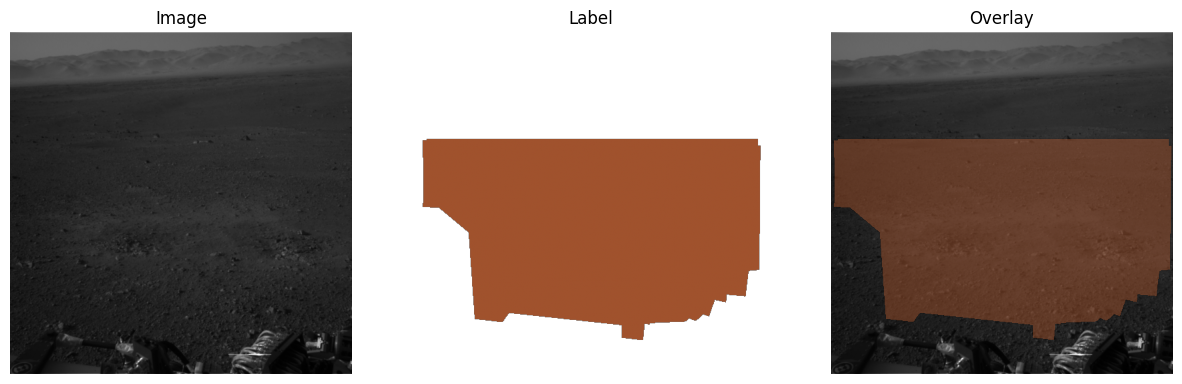

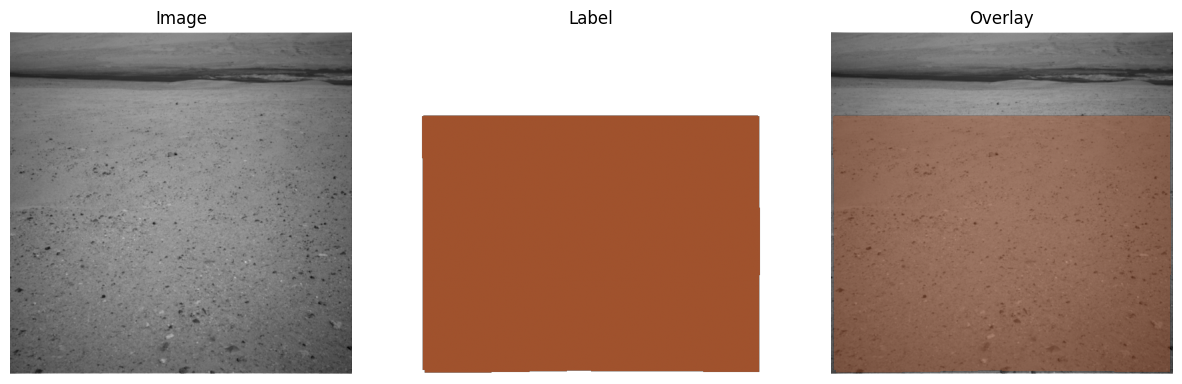

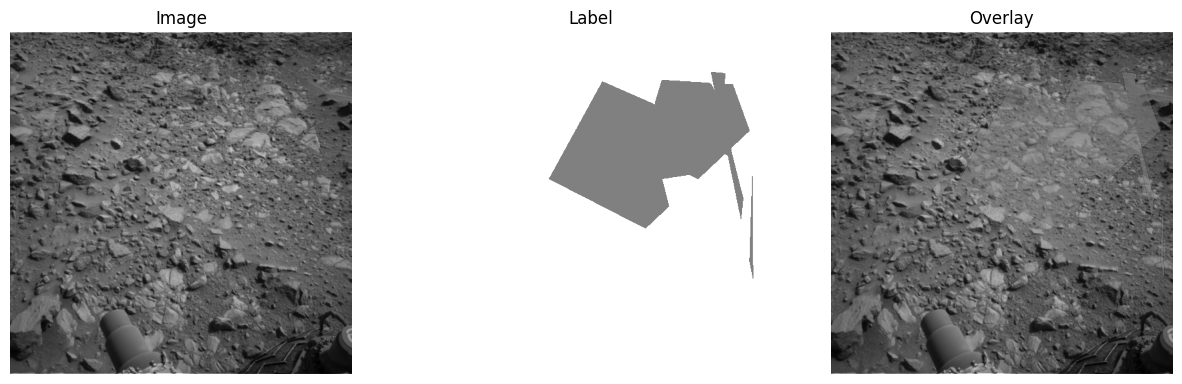

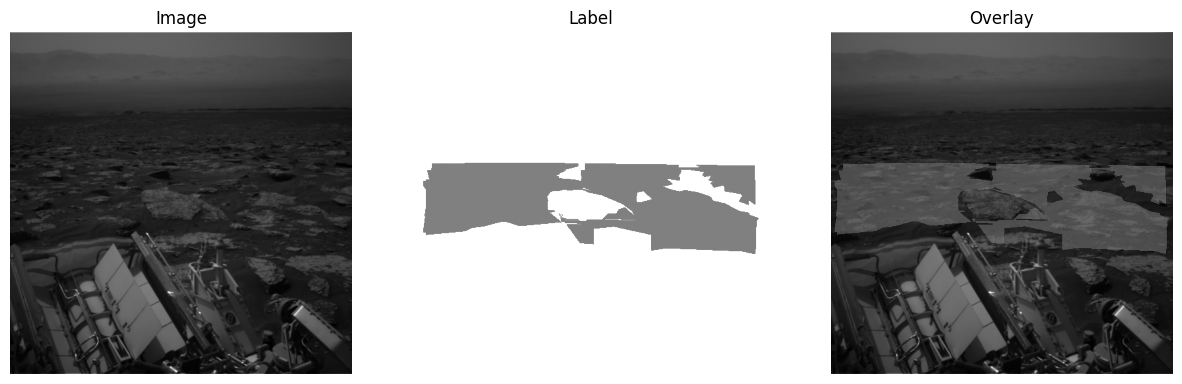

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np 

cmap = ListedColormap(["sienna", "gray", "gold", "red"]) # soil, bedrock, sand, big rock

for i in [0, 100, 5000, 12000]:
    img, lbl = ds[i]
    img_arr = img[0].numpy()
    lbl_arr = lbl.numpy()

    masked = np.ma.masked_equal(lbl_arr, 255) 

    fig, axes = plt.subplots(1, 3, figsize=(15, 5)) 

    axes[0].imshow(img_arr, cmap="gray")
    axes[0].set_title("Image")

    axes[1].imshow(masked, cmap=cmap, vmin=0, vmax=3)
    axes[1].set_title("Label")

    axes[2].imshow(img_arr, cmap="gray")
    axes[2].imshow(masked, cmap=cmap, vmin=0, vmax=3, alpha=0.5) 
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off") 
    plt.show()

In [ ]:
# test the split function 

train_pairs, val_pairs = split_pairs(all_pairs)
print(len(train_pairs))
print(len(val_pairs))

from torch.utils.data import DataLoader

train_ds = MarsTerrainDataset(train_pairs)
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
imgs, lbls = next(iter(train_loader))     # grab one batch
print(imgs.shape, lbls.shape)

print(len(set(train_pairs) & set(val_pairs))) # no overlaps 

14311
1590
torch.Size([8, 1, 512, 512]) torch.Size([8, 512, 512])
0
